In [16]:
from modules.benchmark import *
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# Support Vector Classifier

In [11]:
visco = quick_load(feature='expert_chen',
                   columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(visco)

In [12]:
X[['type_surfactant1', 'type_surfactant2']] = X[['type_surfactant1', 'type_surfactant2']].fillna('None')
X = X.fillna(-1)

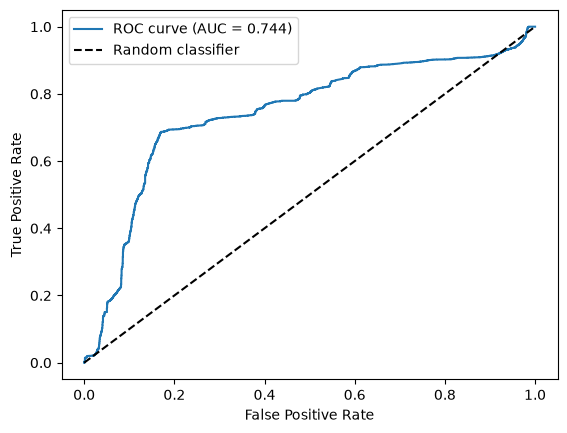

In [17]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = SVC(kernel="rbf", C=1.0, gamma="scale")

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method="decision_function")
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [18]:
roc_auc

0.7438433057952814

In [ ]:
classifier = SVC(kernel="rbf", C=1.0, gamma="scale")

serial_test(classifier, X, y, groups)